# Toto: Zero-Shot Multivariate Forecasting with Datadog's Time Series Foundation Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/toto_zero_shot.ipynb)

**Paper**: *This Time is Different: An Observability Perspective on Time Series Foundation Models*
(Cohen, Khwaja, Doubli, Lemaachi, Lettieri, Masson, Miccinilli, Ramé, Ren, Rosenthal, Wang, Xie — Datadog AI Research), arXiv preprint 2025 — [arXiv:2505.14766](https://arxiv.org/abs/2505.14766)

**Official code**: [github.com/DataDog/toto](https://github.com/DataDog/toto) · **Weights**: [Datadog/Toto-Open-Base-1.0](https://huggingface.co/Datadog/Toto-Open-Base-1.0) (151M params, Apache-2.0) · **Package**: `toto-ts==0.2.0`

**Key ideas**:
- **Decoder-only transformer, pre-trained on ~2.36T points** (mostly Datadog observability metrics + public data + synthetic series).
- **Natively multivariate**: the backbone alternates *time-wise* (causal) and *space-wise* (across-variates) attention, so all channels of a series are forecast **jointly** — unlike Chronos/TimesFM-style models that treat each channel as an independent univariate series.
- **Patch embeddings** of size $P=64$, **causal patch-wise scaling** (mean/std computed only from the past, so it can be used autoregressively).
- **Probabilistic head**: a **mixture of $K=24$ Student-T** distributions per time step. Forecasts are produced by **autoregressive sampling** of whole trajectories; the point forecast is the **median** of the samples.

**What this notebook does**: zero-shot (no training at all) forecasting of all **7 ETTh1 channels jointly** on the shared benchmark of this repo (TSLib splits, horizon $H=96$), with lookback $L=512$ (main setting) and $L=96$.

## 1. Install

Toto pins old versions of everything (`torch==2.7.0`, `numpy==1.26.4`, `transformers==4.52.1`, ...). Installing it normally on Colab would **downgrade torch and numpy** and force a runtime restart. The inference code only needs a handful of light dependencies, so we install the package with `--no-deps` and add just those (`gluonts` for the Student-T distribution, `lightning` because `gluonts.torch` imports it, `rotary-embedding-torch`, `jaxtyping`). Verified with torch 2.12 / numpy 2.3.

In [1]:
%pip install -q --no-deps toto-ts==0.2.0 gluonts==0.16.2 rotary-embedding-torch==0.8.6
%pip install -q jaxtyping lightning

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


## 2. Imports, device, seeds

Toto uses xFormers memory-efficient attention when it is importable, and otherwise falls back to PyTorch's `scaled_dot_product_attention` (which itself dispatches to flash / memory-efficient kernels). Colab does not ship xFormers and installing it would replace torch, so we explicitly **disable the xFormers path** and use SDPA. This also avoids crashes from prebuilt xFormers wheels that do not support a given GPU.

In [2]:
import sys, os, time, json, random, warnings
sys.modules["xformers"] = None          # force the PyTorch SDPA attention path (see above)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from huggingface_hub import snapshot_download
from importlib.metadata import version

from toto.data.util.dataset import MaskedTimeseries
from toto.inference.forecaster import TotoForecaster
from toto.model.toto import Toto

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
print("torch", torch.__version__, "| numpy", np.__version__, "| toto-ts", version("toto-ts"))

device: cuda NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition
torch 2.12.1+cu130 | numpy 2.3.5 | toto-ts 0.2.0


## 3. Data: ETTh1 with the shared benchmark splits

Standard Informer/Autoformer/TSLib borders: 12 / 4 / 4 months for train / val / test. A `StandardScaler` is fitted on the training rows only and metrics are computed on the scaled data (this is what papers report). Toto is zero-shot, so the train and val splits are only used for the scaler.

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
train, val, test512, cols = load_etth1(512)
print("channels:", cols)
print("train", train.shape, "| test (L=512)", test512.shape,
      "| stride-1 test windows:", len(WindowDataset(test512, 512, H)))

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
train (8640, 7) | test (L=512) (3392, 7) | stride-1 test windows: 2785


## 4. Load the pre-trained model

`Toto.from_pretrained(...)` breaks with `huggingface_hub>=1.0` (the hub mixin no longer passes `proxies` / `resume_download`), so we download the snapshot and use the package's own `Toto.load_from_checkpoint`, which reads `config.json` + `model.safetensors`. Works with both old and new `huggingface_hub`.

`TotoForecaster` wraps the backbone and implements the autoregressive decoding loop.

In [4]:
ckpt_dir = snapshot_download("Datadog/Toto-Open-Base-1.0")
toto = Toto.load_from_checkpoint(ckpt_dir, map_location=str(device)).eval()
n_params = sum(p.numel() for p in toto.parameters())
print(f"Toto-Open-Base-1.0: {n_params/1e6:.1f}M parameters")
forecaster = TotoForecaster(toto.model)

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Fetching 6 files: 100%|██████████| 6/6 [00:00<00:00, 118149.41it/s]

Toto-Open-Base-1.0: 151.3M parameters


## 5. Autoregressive sampling & evaluation protocol

Given context $x_{1:L}\in\mathbb{R}^{V\times L}$ (here $V=7$ variates), Toto models
$$p(x_{t+1:t+P}\mid x_{1:t}) = \prod_{v,\tau}\ \sum_{k=1}^{24} \pi_k\, \mathrm{StudentT}\big(x_{v,\tau};\ \nu_k, \mu_k, \sigma_k\big)$$
for the next patch of $P=64$ steps. To forecast $H=96$ steps it samples a patch, appends it to the context and repeats ($\lceil 96/64\rceil=2$ decoding steps). Doing this $S$ times gives $S$ joint trajectories; we take the **per-step median** as the point forecast and sample quantiles for intervals.

Why the median and not the mean of samples: the Student-T mixture is heavy-tailed, and a handful of extreme trajectories make the sample mean useless as a point forecast (in a check on a 64-window subset the mean-of-samples MSE was > 3 vs 0.40 for the median). The paper also uses the median.

**Cost control** (Toto sampling is expensive — every sample is a full autoregressive rollout of a 151M-param model):
- `num_samples = 64` (paper: 256). On a subset, median MSE was 0.398 with 64 vs 0.396 with 256 samples, i.e. 64 is enough for the point forecast.
- Test windows with **stride 8** (349 of the 2785 stride-1 windows), as allowed by the benchmark conventions.
- Documented memory-efficiency options: `use_kv_cache=True` (context is encoded once, decoding steps reuse cached keys/values), `samples_per_batch` (trajectories generated in chunks), and several windows batched together (effective batch = windows x samples_per_batch).
- Kept in **fp32**: fp16 autocast nearly doubled the median MSE (0.71 vs 0.40) on the subset.

Toto also takes `timestamp_seconds` / `time_interval_seconds`; they are placeholders in the released model and are not used for the forecast, we pass zeros and 3600 s.

In [5]:
NUM_SAMPLES = 64          # sample trajectories per window
SAMPLES_PER_BATCH = 64    # trajectories generated per chunk (must divide NUM_SAMPLES)
WINDOW_BATCH = 8          # test windows forecast together (peak ~10 GB at L=512 -> fits a 16 GB T4)
STRIDE = 8                # stride over the test windows
QUANTILES = [0.1, 0.5, 0.9]

@torch.inference_mode()
def toto_forecast(x, num_samples=NUM_SAMPLES):
    # x: (B, L, V) tensor -> samples (B, V, H, S)
    x = x.permute(0, 2, 1).contiguous().to(device)          # Toto layout: (batch, variates, time)
    B, V, _ = x.shape
    inp = MaskedTimeseries(
        series=x,
        padding_mask=torch.ones_like(x, dtype=torch.bool),
        id_mask=torch.zeros_like(x),
        timestamp_seconds=torch.zeros_like(x),
        time_interval_seconds=torch.full((B, V), 3600, device=device),
    )
    fc = forecaster.forecast(inp, prediction_length=H, num_samples=num_samples,
                             samples_per_batch=SAMPLES_PER_BATCH, use_kv_cache=True)
    return fc.samples[:, :, :H]

def evaluate(L, stride=STRIDE):
    seed_everything()
    _, _, test, _ = load_etth1(L)
    ds = WindowDataset(test, L, H, stride=stride)
    dl = torch.utils.data.DataLoader(ds, batch_size=WINDOW_BATCH, shuffle=False)
    preds, qs, trues, ctxs = [], [], [], []
    t0 = time.time()
    for xb, yb in dl:
        s = toto_forecast(xb)                                  # (B, V, H, S)
        q = torch.quantile(s, torch.tensor(QUANTILES, device=s.device), dim=-1)  # (Q, B, V, H)
        qs.append(q.permute(1, 0, 3, 2).cpu().numpy())         # (B, Q, H, V)
        preds.append(q[QUANTILES.index(0.5)].permute(0, 2, 1).cpu().numpy())  # median, (B, H, V)
        trues.append(yb.numpy()); ctxs.append(xb.numpy())
    if device.type == "cuda": torch.cuda.synchronize()
    secs = time.time() - t0
    P, Y, Q = np.concatenate(preds), np.concatenate(trues), np.concatenate(qs)
    res = dict(lookback=L, n_windows=len(ds), stride=stride, seconds=secs,
               mse=float(((P - Y) ** 2).mean()), mae=float(np.abs(P - Y).mean()),
               mse_per_channel=((P - Y) ** 2).mean(axis=(0, 1)),
               coverage_80=float(((Y >= Q[:, 0]) & (Y <= Q[:, 2])).mean()))
    print(f"L={L}: {len(ds)} windows (stride {stride}), {NUM_SAMPLES} samples  ->  "
          f"MSE {res['mse']:.4f}  MAE {res['mae']:.4f}  | 80% PI coverage {res['coverage_80']:.3f}  | {secs:.0f}s")
    return res, dict(P=P, Y=Y, Q=Q, X=np.concatenate(ctxs))

## 6. Zero-shot forecast, lookback $L=512$ (main setting)

All 7 channels are fed as one multivariate series per window; Toto's space-wise attention mixes information across them.

In [6]:
res512, out512 = evaluate(512)
if device.type == "cuda":
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1e9:.1f} GB")

L=512: 349 windows (stride 8), 64 samples  ->  MSE 0.4153  MAE 0.3938  | 80% PI coverage 0.752  | 18s
peak GPU memory: 10.4 GB


## 7. Zero-shot forecast, lookback $L=96$

Same as the supervised baselines' input length. With patch size 64, a 96-step context is only 1.5 patches (left-padded and masked to 128), so Toto has very little history to work with — expect a clearly worse score than with $L=512$.

In [7]:
res96, out96 = evaluate(96)

L=96: 349 windows (stride 8), 64 samples  ->  MSE 0.5606  MAE 0.4619  | 80% PI coverage 0.810  | 26s


## 8. Results

In [8]:
PAPER = {"mse": 0.382, "mae": 0.381}   # Toto zero-shot, ETTh1 H=96 (paper Table 16; stride 1, 256 samples, median)
rows = [
    ("Toto zero-shot, L=512 (this notebook)", res512["mse"], res512["mae"]),
    ("Toto zero-shot, L=96  (this notebook)", res96["mse"], res96["mae"]),
    ("Toto zero-shot (paper, Table 16)", PAPER["mse"], PAPER["mae"]),
    ("DLinear (TSLib, L=96)", 0.386, 0.400),
    ("PatchTST (TSLib, L=96)", 0.414, 0.419),
    ("iTransformer (TSLib, L=96)", 0.386, 0.405),
    ("TimesNet (TSLib, L=96)", 0.384, 0.402),
]
print(f"ETTh1, horizon 96, all 7 channels, scaled data  |  point forecast = median of {NUM_SAMPLES} samples, test stride {STRIDE}")
print(f"{'model':42s} {'MSE':>7s} {'MAE':>7s}")
for n, a, b in rows: print(f"{n:42s} {a:7.4f} {b:7.4f}")
print("\nPer-channel MSE (L=512):", {c: round(float(v), 3) for c, v in zip(cols, res512["mse_per_channel"])})
print(f"Inference time: L=512 {res512['seconds']:.0f}s, L=96 {res96['seconds']:.0f}s")

ETTh1, horizon 96, all 7 channels, scaled data  |  point forecast = median of 64 samples, test stride 8
model                                          MSE     MAE
Toto zero-shot, L=512 (this notebook)       0.4153  0.3938
Toto zero-shot, L=96  (this notebook)       0.5606  0.4619
Toto zero-shot (paper, Table 16)            0.3820  0.3810
DLinear (TSLib, L=96)                       0.3860  0.4000
PatchTST (TSLib, L=96)                      0.4140  0.4190
iTransformer (TSLib, L=96)                  0.3860  0.4050
TimesNet (TSLib, L=96)                      0.3840  0.4020

Per-channel MSE (L=512): {'HUFL': 0.875, 'HULL': 0.221, 'MUFL': 0.912, 'MULL': 0.177, 'LUFL': 0.54, 'LULL': 0.123, 'OT': 0.058}
Inference time: L=512 18s, L=96 26s


**Reading the numbers.** With $L=512$ Toto lands in the range of the supervised TSLib baselines without seeing a single ETTh1 training example, but ~0.03 MSE above the paper's 0.382. The paper does not state the context length used for LSF, and Toto was pre-trained with contexts up to 4096: in a separate check with the same code (stride 16, 64 samples) a context of $L=2048$ gave MSE 0.393 / MAE 0.387 vs 0.415 / 0.393 for $L=512$ on the same windows, so most of the gap is the shorter context. $L=96$ is far too short for a patch-64 model. The 80% intervals are slightly under-dispersed at $L=512$ (coverage ~0.75).

## 9. Forecast plots with quantile bands

Left: the OT (oil temperature) channel for one test window — input history, ground truth, the median forecast and the 10–90% band from the sample trajectories. Right: all 7 channels of the same window, forecast jointly.

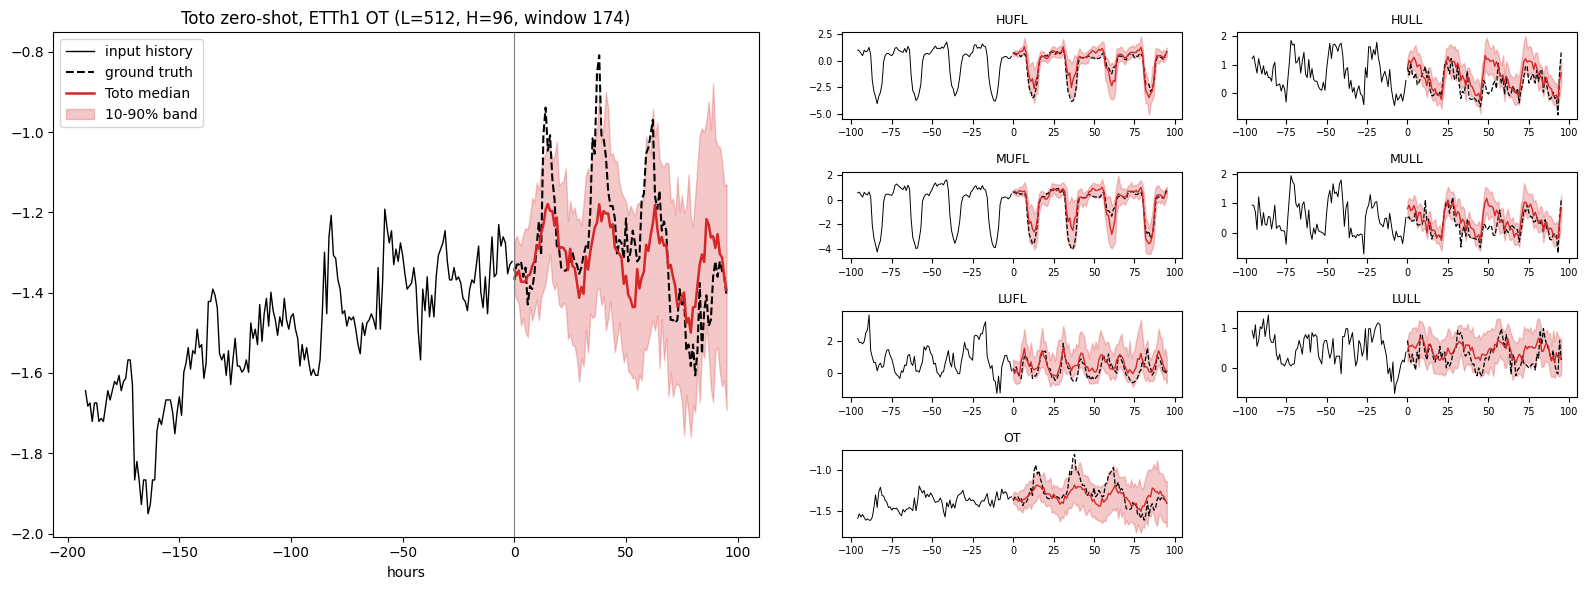

In [9]:
k = len(out512["P"]) // 2
X, Y, Q, P = out512["X"][k], out512["Y"][k], out512["Q"][k], out512["P"][k]
ot = cols.index("OT"); hist = 192
t_in, t_out = np.arange(-hist, 0), np.arange(H)

fig = plt.figure(figsize=(16, 6))
ax = fig.add_subplot(1, 2, 1)
ax.plot(t_in, X[-hist:, ot], color="k", lw=1, label="input history")
ax.plot(t_out, Y[:, ot], color="k", lw=1.5, ls="--", label="ground truth")
ax.plot(t_out, P[:, ot], color="C3", lw=1.8, label="Toto median")
ax.fill_between(t_out, Q[0, :, ot], Q[2, :, ot], color="C3", alpha=0.25, label="10-90% band")
ax.axvline(0, color="gray", lw=0.8)
ax.set_title(f"Toto zero-shot, ETTh1 OT (L=512, H={H}, window {k})"); ax.set_xlabel("hours"); ax.legend()

for v in range(len(cols)):
    a = fig.add_subplot(4, 4, [3, 4, 7, 8, 11, 12, 15][v])
    a.plot(t_in[-96:], X[-96:, v], color="k", lw=0.7)
    a.plot(t_out, Y[:, v], color="k", lw=0.9, ls="--")
    a.plot(t_out, P[:, v], color="C3", lw=1)
    a.fill_between(t_out, Q[0, :, v], Q[2, :, v], color="C3", alpha=0.25)
    a.set_title(cols[v], fontsize=9); a.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

## 10. Save results

In [10]:
try:
    results = {
        "model": "Toto (Toto-Open-Base-1.0, 151M)",
        "paper": "This Time is Different: An Observability Perspective on Time Series Foundation Models (arXiv:2505.14766)",
        "venue": "arXiv preprint 2025 (Datadog)",
        "type": "zero-shot foundation",
        "lookback": 512, "horizon": H,
        "mse": res512["mse"], "mae": res512["mae"],
        "paper_mse": PAPER["mse"], "paper_mae": PAPER["mae"],
        "params": int(n_params),
        "train_or_infer_seconds": round(res512["seconds"], 1),
        "stride": STRIDE, "n_test_windows": res512["n_windows"],
        "num_samples": NUM_SAMPLES, "point_forecast": "median of samples",
        "coverage_80": res512["coverage_80"],
        "lookback_96": {"mse": res96["mse"], "mae": res96["mae"], "coverage_80": res96["coverage_80"],
                        "infer_seconds": round(res96["seconds"], 1), "n_test_windows": res96["n_windows"]},
        "package": "toto-ts==" + version("toto-ts"),
        "notes": (f"All 7 channels forecast jointly (Toto is natively multivariate). Test windows stride {STRIDE} "
                  f"(not stride 1), {NUM_SAMPLES} samples, point forecast = median, fp32, KV cache, SDPA attention. "
                  "Paper number: stride 1, 256 samples, median, context length not stated for LSF."),
    }
    with open(f"results_toto_zero_shot.json", "w") as f: json.dump(results, f, indent=2)
    print(json.dumps(results, indent=2))
except Exception as e:
    print("could not write results:", e)

{
  "model": "Toto (Toto-Open-Base-1.0, 151M)",
  "paper": "This Time is Different: An Observability Perspective on Time Series Foundation Models (arXiv:2505.14766)",
  "venue": "arXiv preprint 2025 (Datadog)",
  "type": "zero-shot foundation",
  "lookback": 512,
  "horizon": 96,
  "mse": 0.4152548313140869,
  "mae": 0.3937593400478363,
  "paper_mse": 0.382,
  "paper_mae": 0.381,
  "params": 151306080,
  "train_or_infer_seconds": 17.9,
  "stride": 8,
  "n_test_windows": 349,
  "num_samples": 64,
  "point_forecast": "median of samples",
  "coverage_80": 0.7519784418065221,
  "lookback_96": {
    "mse": 0.5605559349060059,
    "mae": 0.4619126617908478,
    "coverage_80": 0.8102273502524219,
    "infer_seconds": 26.0,
    "n_test_windows": 349
  },
  "package": "toto-ts==0.2.0",
  "notes": "All 7 channels forecast jointly (Toto is natively multivariate). Test windows stride 8 (not stride 1), 64 samples, point forecast = median, fp32, KV cache, SDPA attention. Paper number: stride 1, 256 

## Using your own data

```python
arr = your_dataframe[["sensor_a", "sensor_b", "target"]].values.astype("float32")   # (time, variates)
x = torch.from_numpy(arr[-512:])[None]           # (1, L, V): last 512 steps as context
samples = toto_forecast(x, num_samples=64)       # (1, V, H, S); change H above for another horizon
median = samples.median(-1).values               # point forecast, (1, V, H)
lo, hi = samples.quantile(0.1, -1), samples.quantile(0.9, -1)
```

Tips:
- No scaling needed — Toto normalises each series internally (causal patch scaler). Pass related series together as variates so the space-wise attention can use them.
- Longer context helps (the model was pre-trained with up to 4096 steps); the cost grows with $L$, $V$ and the number of samples.
- More samples give smoother quantiles; reduce `WINDOW_BATCH` / `SAMPLES_PER_BATCH` if you run out of GPU memory.
- Missing values: set the corresponding entries of `padding_mask` to `False`.